# P3.01 — Who cuts the municipal IMI rate, and when?

**Questions:** RQ7.4 (who benefits from IMI cuts; here, the groundwork). Before estimating whether cuts
are capitalised into prices (`p3_02`), look at the treatment: how many municipalities change the urban rate
each year, how big the changes are, which of them are clean enough to use, and whether the municipalities
that cut differ from those that do not *before* they cut. Rates are chosen by councils, so a difference
before the cut would mean the comparison is not like for like.

**Data:** Portal das Finanças urban IMI rate per municipality and tax year (2012 to 2025), in the panel as
`imi_urban_pct` and `imi_change_pp`. Mainland only (278 municipalities); the islands use a different code
scheme and have few events. Real price per m² from INE. Definitions in `src/pthousing/analysis/causal.py`.

In [1]:
import numpy as np
import pandas as pd

from pthousing.analysis import causal
from pthousing.data import build_panel, typology
from pthousing.viz import charts, style

style.apply_style()
panel = build_panel.read("panel_municipality_year")
muni_typology = typology.read()
frame = causal.build_frame(panel)
mainland = frame[frame["territory"] == "continente"]
print(mainland["muni_code"].nunique(), "mainland municipalities")

278 mainland municipalities


## Step 1 — Rate changes per year
A change is the difference between this tax year's rate and last year's, so 2013 is the first year with a change.
Municipality-years with parish-specific rates have no single rate and no change.

In [2]:
g = mainland[mainland["year"] >= 2013].groupby("year")
by_year = pd.DataFrame(
    {
        "cuts": g["change_pp"].apply(lambda s: (s < -causal.TOLERANCE).sum()),
        "increases": g["change_pp"].apply(lambda s: (s > causal.TOLERANCE).sum()),
        "unchanged": g["change_pp"].apply(lambda s: (s.abs() <= causal.TOLERANCE).sum()),
        "missing": g["change_pp"].apply(lambda s: s.isna().sum()),
        "at_floor_pct": g["rate_pct"].apply(
            lambda s: 100 * (s <= causal.RATE_FLOOR_PCT + causal.TOLERANCE).sum() / s.notna().sum()
        ),
        "median_rate_pct": g["rate_pct"].median(),
    }
).reset_index()
style.save_table(by_year.round(2), "p3", "rate_changes_by_year")
by_year.round(2)

,year,cuts,increases,unchanged,missing,at_floor_pct,median_rate_pct
0,2013,64,18,196,0,42.45,0.35
1,2014,30,19,228,1,41.16,0.35
2,2015,39,4,226,9,41.26,0.35
3,2016,87,0,179,12,44.69,0.33
4,2017,47,8,212,11,45.72,0.32
5,2018,48,4,213,13,47.60,0.32
6,2019,43,1,225,9,48.18,0.32
7,2020,84,0,188,6,54.38,0.30
8,2021,39,2,230,7,55.51,0.30
9,2022,43,2,223,10,57.78,0.30


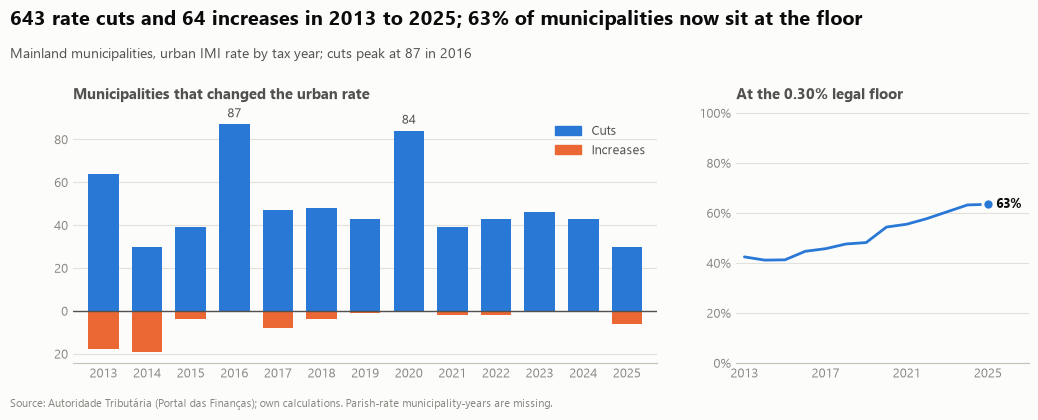

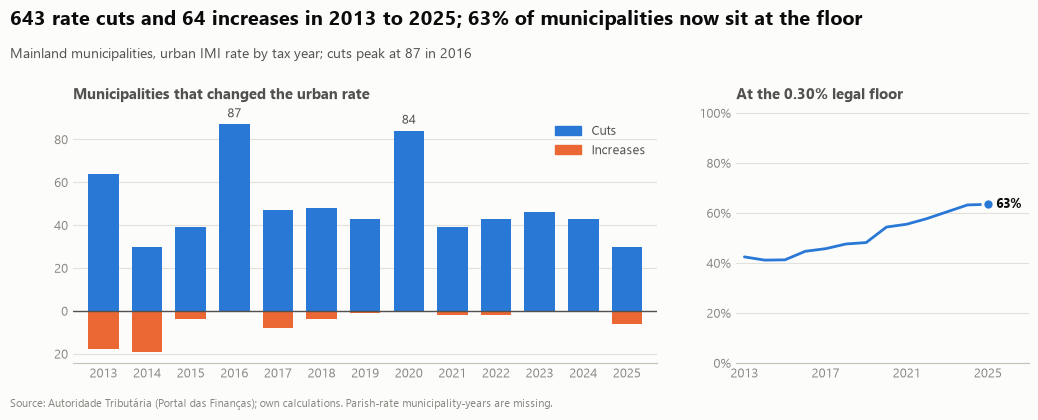

In [3]:
fig = charts.imi_rate_changes(by_year)
style.save_fig(fig, "p3", "rate_changes_by_year")
fig

Cuts are the rule: increases are rare after 2015 (8 in 2017, none in 2016, 2020 or 2023). Two waves stand out,
2016 and 2020, when 87 and 84 municipalities cut at once. The 2016 wave has no price history before it (prices
start in 2016) and 2020 is the pandemic year, so both are likely to carry common shocks; `p3_03` runs the event
study without 2020. By 2025 about 63% of municipalities are at the 0.30% floor and cannot cut again.

## Step 2 — How large are the changes, and how many are usable?
*Isolated* cut: no other change in the rate from two years before to one year after, with all those years
observed. Only these give a clean before and after.

In [4]:
events = causal.rate_events(mainland)
cuts = events[(events["change_pp"] < -causal.TOLERANCE) & events["event_year"].between(2018, 2023)]
sizes = pd.DataFrame(
    {
        "all cuts 2018-2023": cuts["change_pp"].describe(),
        "with the window observed": cuts.loc[cuts["observed"], "change_pp"].describe(),
        "isolated": cuts.loc[cuts["isolated"], "change_pp"].describe(),
    }
).T
count = (
    pd.DataFrame(
        {
            "all cuts": cuts.groupby("event_year").size(),
            "window observed": cuts[cuts["observed"]].groupby("event_year").size(),
            "isolated": cuts[cuts["isolated"]].groupby("event_year").size(),
            "isolated, at least 0.03 pp": cuts[
                cuts["isolated"] & (cuts["change_pp"] <= -0.03 + 1e-9)
            ]
            .groupby("event_year")
            .size(),
        }
    )
    .fillna(0)
    .astype(int)
)
count.loc["total"] = count.sum()
style.save_table(
    count.reset_index().rename(columns={"index": "event_year"}), "p3", "events_by_year"
)
print(sizes.round(3))
count

                          count   mean    std   min    25%   50%   75%    max
all cuts 2018-2023        303.0 -0.019  0.017 -0.15 -0.020 -0.01 -0.01 -0.001
with the window observed  295.0 -0.019  0.017 -0.15 -0.020 -0.01 -0.01 -0.001
isolated                   68.0 -0.028  0.027 -0.15 -0.032 -0.02 -0.01 -0.005


,all cuts,window observed,isolated,"isolated, at least 0.03 pp"
event_year,,,,
2018,48,47,9,3
2019,43,42,4,1
2020,84,81,31,8
2021,39,36,5,3
2022,43,43,5,1
2023,46,46,14,6
total,303,295,68,22


Of 295 cuts with a usable window only 68 are isolated, most of them small (median 0.02 pp, about 6% of the
bill) and 31 of them in the 2020 wave. This is the whole sample the event study can use.

## Step 3 — Do municipalities that cut look different before the cut?
For each event year, the isolated cutters against municipalities whose rate did not change from two years before
to two years after (the controls the event study uses). Means of the characteristics measured *before* the cut:
real price growth over the year before the cut (from two years to one year before), the price level, the rate, the typology.

In [5]:
stacks = causal.build_stacks(mainland)
wide = stacks.pivot_table(index=["stack", "muni_code"], columns="k", values="y")
meta = stacks.drop_duplicates(["stack", "muni_code"]).set_index(["stack", "muni_code"])
rate = mainland.set_index(["muni_code", "year"])["rate_pct"]
who = pd.DataFrame(
    {
        "treated": meta["treated"],
        "price_growth_before_pct": 100 * (wide[-1] - wide[-2]),
        "price_real_eur_sqm": np.exp(wide[-1]),
    }
)
who["rate_before_pct"] = [rate.get((code, stack - 1), np.nan) for stack, code in who.index]
who = who.reset_index().merge(
    muni_typology[["muni_code", "coast_class", "density_class", "tourist"]],
    on="muni_code",
    how="left",
)
who["coast"] = who["coast_class"].eq("coast")
who["urban"] = who["density_class"].eq("urban")
who["tourist_area"] = who["tourist"].ne("other")
rows = {
    "real price growth in the year before the cut (%)": "price_growth_before_pct",
    "real price (EUR per m2) the year before": "price_real_eur_sqm",
    "rate the year before (%)": "rate_before_pct",
    "on the coast (share)": "coast",
    "urban (share)": "urban",
    "tourist municipality (share)": "tourist_area",
}
table = []
for label, col in rows.items():
    t, c = who.loc[who["treated"], col].astype(float), who.loc[~who["treated"], col].astype(float)
    se = np.sqrt(t.var() / t.count() + c.var() / c.count())
    table.append(
        {
            "characteristic": label,
            "cutters": t.mean(),
            "controls": c.mean(),
            "difference": t.mean() - c.mean(),
            "t_stat": (t.mean() - c.mean()) / se,
            "n_cutters": int(t.count()),
            "n_controls": int(c.count()),
        }
    )
who_table = pd.DataFrame(table)
style.save_table(who_table.round(3), "p3", "who_cuts")
who_table.round(3)

,characteristic,cutters,controls,difference,t_stat,n_cutters,n_controls
0,real price growth in the year before the cut (%),9.687,4.464,5.223,3.684,65,757
1,real price (EUR per m2) the year before,976.384,785.652,190.732,2.935,65,757
2,rate the year before (%),0.373,0.314,0.059,13.471,65,757
3,on the coast (share),0.231,0.148,0.083,1.527,65,757
4,urban (share),0.231,0.032,0.199,3.752,65,757
5,tourist municipality (share),0.108,0.127,-0.019,-0.471,65,757


Reading: municipalities that cut were **not** like those that did not. In the year before the cut their real
prices grew about 5 pp faster (9.7% against 4.5%, t = 3.7), they are more urban and pricier, and they start
from higher rates (they have room to cut; many controls sit at the floor). So cuts follow booms, which is the
selection the design worried about, and the pre-period coefficients of `p3_02` test it formally. The comparison in the event study is within NUTS 3 region and year, so regional differences in these
rows are partly removed there; this table is the raw version.

In [6]:
# which regions the cutters are in (clusters of events would weaken the within-region comparison)
region_counts = (
    stacks[stacks["treated"]]
    .drop_duplicates(["stack", "muni_code"])
    .groupby("region")
    .size()
    .sort_values(ascending=False)
)
print(region_counts.head(8).to_string())
print(f"{region_counts.size} NUTS 3 regions with at least one treated municipality")

region
Douro                        8
Médio Tejo                   6
Oeste                        5
Região de Coimbra            4
Algarve                      4
Alentejo Central             4
Ave                          4
Beiras e Serra da Estrela    4
19 NUTS 3 regions with at least one treated municipality


## Step 4 — Two data checks flagged when the rates were ingested
1. **Are the 2025 rates complete?** Compare 2025 with the earlier years: the number of municipalities with a
   rate and the number of changes.
2. **Parish links.** The portal shows a "Taxas por freguesia" link for 71 to 79 municipalities a year in
   2013 to 2024 but for 8 in 2025. Whether the municipal rate is then the effective rate is not verified, so
   `p3_03` runs the event study with and without the municipalities that ever show the link.

In [7]:
coverage = mainland.groupby("year").agg(
    with_rate=("rate_pct", "count"),
    parish_link=("parish_rates", lambda s: int(s.fillna(False).sum())),
    deduction_link=("deduction_link", lambda s: int(s.fillna(False).sum())),
)
coverage = coverage.loc[2012:2025]
coverage["changes"] = by_year.set_index("year")[["cuts", "increases"]].sum(axis=1)
style.save_table(coverage.reset_index(), "p3", "rate_coverage_by_year")
coverage.T

year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
with_rate,278,278,277,269,273,269,271,274,274,272,270,271,272,271
parish_link,206,71,71,79,74,77,76,73,73,76,76,74,75,7
deduction_link,0,0,0,0,193,211,216,218,227,238,243,241,249,251
changes,NaN,82.0,49.0,43.0,87.0,55.0,52.0,44.0,84.0,41.0,45.0,46.0,43.0,36.0


In [8]:
# the 2012 pages show the link for 206 municipalities (another convention), so "ever" counts from 2013
since_2013 = mainland[mainland["year"] >= causal.PARISH_LINK_FROM]
ever_parish = since_2013.groupby("muni_code")["parish_rates"].apply(
    lambda s: bool(s.fillna(False).any())
)
isolated = events[
    events["isolated"] & (events["change_pp"] < 0) & events["event_year"].between(2018, 2023)
]
linked = isolated["muni_code"].map(ever_parish).fillna(False)
print(
    f"{int(ever_parish.sum())} of {len(ever_parish)} municipalities show the parish link in some year from 2013"
)
print(
    f"isolated cuts 2018-2023: {int((~linked).sum())} in municipalities without the link, {int(linked.sum())} with it"
)

102 of 278 municipalities show the parish link in some year from 2013
isolated cuts 2018-2023: 38 in municipalities without the link, 30 with it


The 2025 rates look complete (about the same number of municipalities with a rate and of changes as in earlier
years), so the drop of the parish link to 7 municipalities in 2025 is a change in what the portal shows, not
missing rates. The meaning of the link is still unverified; the sensitivity run drops the municipalities that
ever show it.

## What this means for `p3_02`
- The usable sample is small (68 isolated cuts, 22 of at least 0.03 pp) and dominated by small cuts: the
  estimate will be imprecise and is reported as an interval against full capitalisation.
- Treated and control municipalities are compared before the cut in the table above; the formal test is the
  pre-period coefficients of the event study.
- The 2020 wave (31 isolated cuts) is almost half the treated sample, so the result without it matters.